In [2]:
import os
import json
import random
import pickle
import datetime

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

from tensorflow.keras import layers
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

2026-10-27 01:42:51.012474: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1793065371.149064      57 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1793065371.187108      57 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1793065371.506026      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793065371.506065      57 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1793065371.506068      57 computation_placer.cc:177] computation placer alr

In [3]:
SEEDS = [42, 123, 2024, 3407, 777]

BATCH_SIZE = 32
EPOCHS = 50
PATIENCE = 5
IMAGE_SIZE = (224, 224)
LEARNING_RATE = 1e-5
FINE_TUNE_LAYERS = 20
AUTOTUNE = tf.data.AUTOTUNE

EXPERIMENT_NAME = "ResNet50_7class"
EXPECTED_NUM_CLASSES = 7

In [4]:
DATASET_DIR = "/kaggle/input/datasets/shahadhossin567r7455/potato-leaf-disease-dataset/Potato Leaf DIsease"

print("Dataset directory:", DATASET_DIR)


Dataset directory: /kaggle/input/datasets/shahadhossin567r7455/potato-leaf-disease-dataset/Potato Leaf DIsease


In [5]:
class_names = sorted([
    folder for folder in os.listdir(DATASET_DIR)
    if os.path.isdir(os.path.join(DATASET_DIR, folder))
])

NUM_CLASSES = len(class_names)

print("Detected classes:")
for i, class_name in enumerate(class_names):
    print(f"{i}: {class_name}")

print("Number of classes:", NUM_CLASSES)

assert NUM_CLASSES == EXPECTED_NUM_CLASSES, f"Expected {EXPECTED_NUM_CLASSES}, found {NUM_CLASSES}"


Detected classes:
0: Early Blight
1: Fungal Diseases
2: Healthy
3: Late Blight
4: Plant Pests
5: Potato Cyst Nematode
6: Potato Virus
Number of classes: 7


In [6]:
valid_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

file_paths = []
labels = []

for label_index, class_name in enumerate(class_names):
    class_dir = os.path.join(DATASET_DIR, class_name)

    for fname in sorted(os.listdir(class_dir)):
        if fname.lower().endswith(valid_extensions):
            file_paths.append(os.path.join(class_dir, fname))
            labels.append(label_index)

file_paths = np.array(file_paths)
labels = np.array(labels)

print("Total images:", len(labels))

unique, counts = np.unique(labels, return_counts=True)
print("\nClass distribution:")
for idx, count in zip(unique, counts):
    print(f"{class_names[idx]}: {count}")


Total images: 3500

Class distribution:
Early Blight: 500
Fungal Diseases: 500
Healthy: 500
Late Blight: 500
Plant Pests: 500
Potato Cyst Nematode: 500
Potato Virus: 500


In [7]:
def load_dataset_resnet50(file_paths, labels, augment=False, shuffle=True, seed=None):
    ds = tf.data.Dataset.from_tensor_slices((file_paths, labels))

    def process(path, label):
        image = tf.io.read_file(path)
        image = tf.image.decode_image(image, channels=3, expand_animations=False)
        image.set_shape([None, None, 3])

        image = tf.image.resize(image, IMAGE_SIZE)
        image = tf.cast(image, tf.float32)

        if augment:
            image = tf.image.random_flip_left_right(image)
            image = tf.image.random_brightness(image, max_delta=25.5)
            image = tf.image.random_contrast(image, lower=0.9, upper=1.1)
            image = tf.clip_by_value(image, 0.0, 255.0)

        image = preprocess_input(image)
        label = tf.one_hot(label, depth=NUM_CLASSES)

        return image, label

    ds = ds.map(process, num_parallel_calls=AUTOTUNE)

    if shuffle:
        ds = ds.shuffle(
            buffer_size=len(file_paths),
            seed=seed,
            reshuffle_each_iteration=True
        )

    ds = ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

    return ds

In [8]:
def build_resnet50(num_classes, input_shape=(224, 224, 3)):
    inputs = tf.keras.Input(shape=input_shape)

    backbone = ResNet50(
        include_top=False,
        weights="imagenet",
        input_tensor=inputs
    )

    backbone.trainable = True

    for layer in backbone.layers[:-FINE_TUNE_LAYERS]:
        layer.trainable = False

    # Keep BatchNormalization statistics frozen
    for layer in backbone.layers:
        if isinstance(layer, layers.BatchNormalization):
            layer.trainable = False

    x = backbone.output
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.2)(x)
    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = tf.keras.Model(
        inputs=inputs,
        outputs=outputs,
        name="ResNet50_7class_finetuned"
    )

    return model

In [9]:
def count_model_parameters(model):
    total_params = model.count_params()

    trainable_params = np.sum([
        np.prod(v.shape) for v in model.trainable_weights
    ])

    non_trainable_params = np.sum([
        np.prod(v.shape) for v in model.non_trainable_weights
    ])

    print(f"Total parameters: {total_params:,}")
    print(f"Trainable parameters: {trainable_params:,}")
    print(f"Non-trainable parameters: {non_trainable_params:,}")

    return total_params, trainable_params, non_trainable_params


In [10]:

def run_single_seed(seed):
    print("\n" + "=" * 70)
    print(f"Running seed: {seed}")
    print("=" * 70)

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)

    X_train, X_temp, y_train, y_temp = train_test_split(
        file_paths,
        labels,
        test_size=0.20,
        stratify=labels,
        random_state=seed
    )

    X_val, X_test, y_val, y_test = train_test_split(
        X_temp,
        y_temp,
        test_size=0.50,
        stratify=y_temp,
        random_state=seed
    )

    print(f"Train: {len(X_train)}")
    print(f"Validation: {len(X_val)}")
    print(f"Test: {len(X_test)}")

    class_weight_vals = compute_class_weight(
        class_weight="balanced",
        classes=np.arange(NUM_CLASSES),
        y=y_train
    )
    class_weight = dict(enumerate(class_weight_vals))

    print("Class weights:", class_weight)

    train_ds = load_dataset_resnet50(
        X_train, y_train, augment=True, shuffle=True, seed=seed
    )
    val_ds = load_dataset_resnet50(
        X_val, y_val, augment=False, shuffle=False, seed=seed
    )
    test_ds = load_dataset_resnet50(
        X_test, y_test, augment=False, shuffle=False, seed=seed
    )

    model = build_resnet50(num_classes=NUM_CLASSES)

    total_params, trainable_params, non_trainable_params = (
        count_model_parameters(model)
    )

    model.compile(
        optimizer=tf.keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),
        loss="categorical_crossentropy",
        metrics=["accuracy"]
    )

    os.makedirs("models", exist_ok=True)
    os.makedirs("history", exist_ok=True)
    os.makedirs("reports", exist_ok=True)
    os.makedirs("predictions", exist_ok=True)

    run_name = f"{EXPERIMENT_NAME}_seed_{seed}"

    model_path = f"models/{run_name}.keras"
    history_path = f"history/{run_name}_history.pkl"
    plot_path = f"history/{run_name}_accuracy_loss.png"
    cm_path = f"history/{run_name}_confusion_matrix.png"
    report_path = f"reports/{run_name}_classification_report.json"
    predictions_path = f"predictions/{run_name}_test_predictions.csv"

    early_stop = EarlyStopping(
        monitor="val_loss",
        patience=PATIENCE,
        restore_best_weights=True
    )

    checkpoint = ModelCheckpoint(
        model_path,
        monitor="val_loss",
        save_best_only=True
    )

    history = model.fit(
        train_ds,
        validation_data=val_ds,
        epochs=EPOCHS,
        callbacks=[early_stop, checkpoint],
        class_weight=class_weight
    )

    stopped_epoch = len(history.history["loss"])
    best_epoch = int(np.argmin(history.history["val_loss"]) + 1)

    with open(history_path, "wb") as f:
        pickle.dump(history.history, f)

    test_loss, test_acc = model.evaluate(test_ds, verbose=0)

    # Collect predictions and probabilities
    y_true = []
    y_pred = []
    all_probs = []

    for images, batch_labels in test_ds:
        probs = model.predict(images, verbose=0)

        y_true.extend(
            np.argmax(batch_labels.numpy(), axis=1)
        )
        y_pred.extend(np.argmax(probs, axis=1))
        all_probs.extend(probs)

    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    all_probs = np.array(all_probs)

    # Save probabilities for future three-way decision analysis
    predictions_df = pd.DataFrame({
        "file_path": X_test,
        "true_label": y_true,
        "predicted_label": y_pred,
        "confidence": np.max(all_probs, axis=1),
        "correct": (y_true == y_pred).astype(int)
    })

    for i, class_name in enumerate(class_names):
        predictions_df[f"prob_class_{i}"] = all_probs[:, i]

    predictions_df.to_csv(predictions_path, index=False)

    report_dict = classification_report(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=class_names,
        digits=4,
        output_dict=True,
        zero_division=0
    )

    with open(report_path, "w") as f:
        json.dump(report_dict, f, indent=4)

    print(f"\nSeed {seed} Test Accuracy: {test_acc:.4f}")
    print(f"Seed {seed} Test Loss: {test_loss:.4f}")
    print(f"Seed {seed} Stopped Epoch: {stopped_epoch}")
    print(f"Seed {seed} Best Epoch: {best_epoch}")

    print("\nClassification Report:")
    print(classification_report(
        y_true,
        y_pred,
        labels=np.arange(NUM_CLASSES),
        target_names=class_names,
        digits=4,
        zero_division=0
    ))

    cm = confusion_matrix(
        y_true, y_pred, labels=np.arange(NUM_CLASSES)
    )

    fig, ax = plt.subplots(figsize=(10, 10))
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )
    disp.plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        xticks_rotation=45
    )
    plt.title(f"Confusion Matrix - Seed {seed}")
    plt.tight_layout()
    plt.savefig(cm_path, dpi=300)
    plt.show()
    plt.close(fig)

    fig = plt.figure(figsize=(12, 5))

    plt.subplot(1, 2, 1)
    plt.plot(history.history["accuracy"], label="Train Accuracy")
    plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
    plt.title(f"Accuracy - Seed {seed}")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history.history["loss"], label="Train Loss")
    plt.plot(history.history["val_loss"], label="Validation Loss")
    plt.title(f"Loss - Seed {seed}")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()

    plt.tight_layout()
    plt.savefig(plot_path, dpi=300)
    plt.show()
    plt.close(fig)

    return {
        "seed": seed,
        "num_classes": NUM_CLASSES,
        "test_accuracy": test_acc,
        "test_loss": test_loss,
        "stopped_epoch": stopped_epoch,
        "best_epoch": best_epoch,
        "macro_precision": report_dict["macro avg"]["precision"],
        "macro_recall": report_dict["macro avg"]["recall"],
        "macro_f1": report_dict["macro avg"]["f1-score"],
        "weighted_precision": report_dict["weighted avg"]["precision"],
        "weighted_recall": report_dict["weighted avg"]["recall"],
        "weighted_f1": report_dict["weighted avg"]["f1-score"],
        "total_params": total_params,
        "trainable_params": trainable_params,
        "non_trainable_params": non_trainable_params,
        "model_path": model_path,
        "history_path": history_path,
        "plot_path": plot_path,
        "confusion_matrix_path": cm_path,
        "classification_report_path": report_path,
        "predictions_path": predictions_path
    }



Running seed: 42
Train: 2800
Validation: 350
Test: 350
Class weights: {0: np.float64(1.0), 1: np.float64(1.0), 2: np.float64(1.0), 3: np.float64(1.0), 4: np.float64(1.0), 5: np.float64(1.0), 6: np.float64(1.0)}


I0000 00:00:1793065396.021918      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1793065396.028189      57 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step
Total parameters: 23,602,055
Trainable parameters: 8,933,383
Non-trainable parameters: 14,668,672
Epoch 1/50


I0000 00:00:1793065417.998614     131 service.cc:152] XLA service 0x7bd41c1166f0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793065417.998665     131 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1793065417.998672     131 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1793065419.952908     131 cuda_dnn.cc:529] Loaded cuDNN version 91002


 1/88 ━━━━━━━━━━━━━━━━━━━━ 32:49 23s/step - accuracy: 0.1562 - loss: 2.2569

I0000 00:00:1793065427.216925     131 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


88/88 ━━━━━━━━━━━━━━━━━━━━ 48s 292ms/step - accuracy: 0.2860 - loss: 1.8629 - val_accuracy: 0.6829 - val_loss: 0.9147
Epoch 2/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 14s 120ms/step - accuracy: 0.6903 - loss: 0.8153 - val_accuracy: 0.8143 - val_loss: 0.5282
Epoch 3/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 14s 121ms/step - accuracy: 0.8187 - loss: 0.5119 - val_accuracy: 0.8686 - val_loss: 0.3766
Epoch 4/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 14s 123ms/step - accuracy: 0.8934 - loss: 0.3009 - val_accuracy: 0.8943 - val_loss: 0.3009
Epoch 5/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 15s 124ms/step - accuracy: 0.9259 - loss: 0.2115 - val_accuracy: 0.9200 - val_loss: 0.2769
Epoch 6/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 15s 126ms/step - accuracy: 0.9446 - loss: 0.1454 - val_accuracy: 0.9229 - val_loss: 0.2552
Epoch 7/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 14s 116ms/step - accuracy: 0.9646 - loss: 0.0930 - val_accuracy: 0.9086 - val_loss: 0.2590
Epoch 8/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 14s 117ms/step - accuracy: 0.9792 - loss: 0.0666 - val_accuracy: 0.917

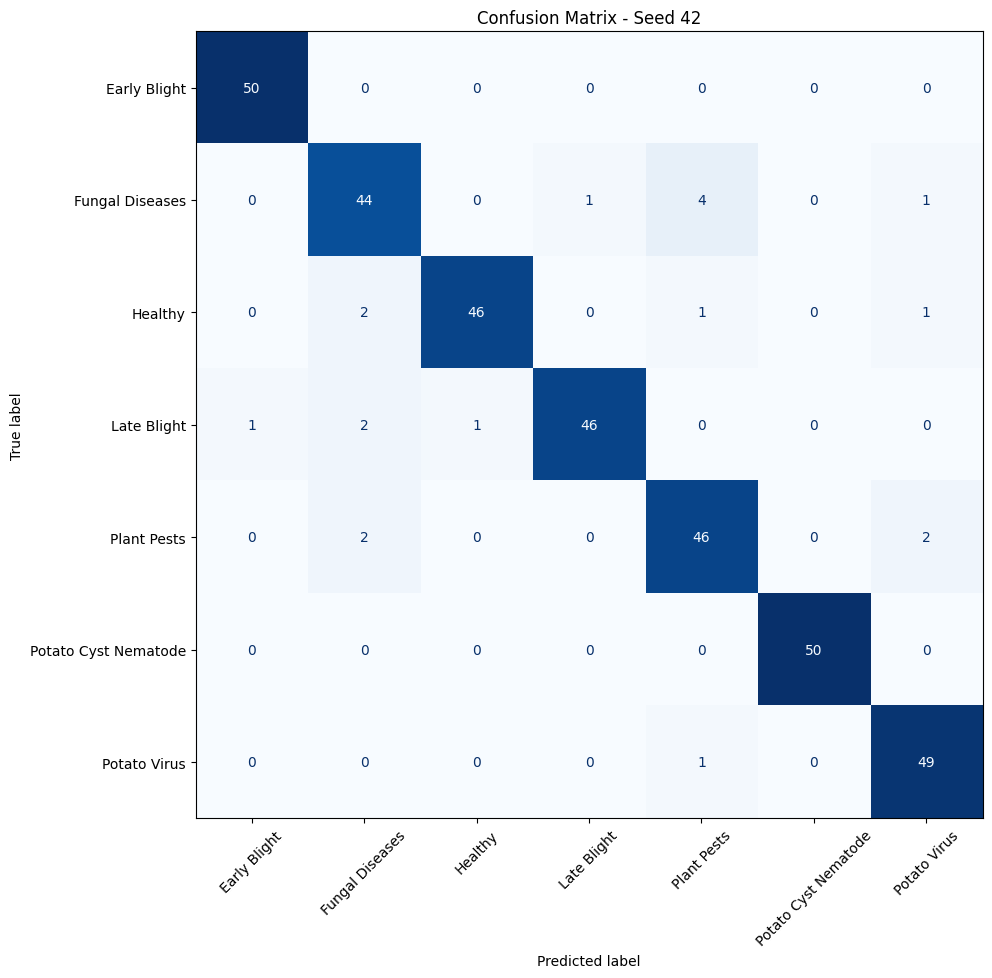

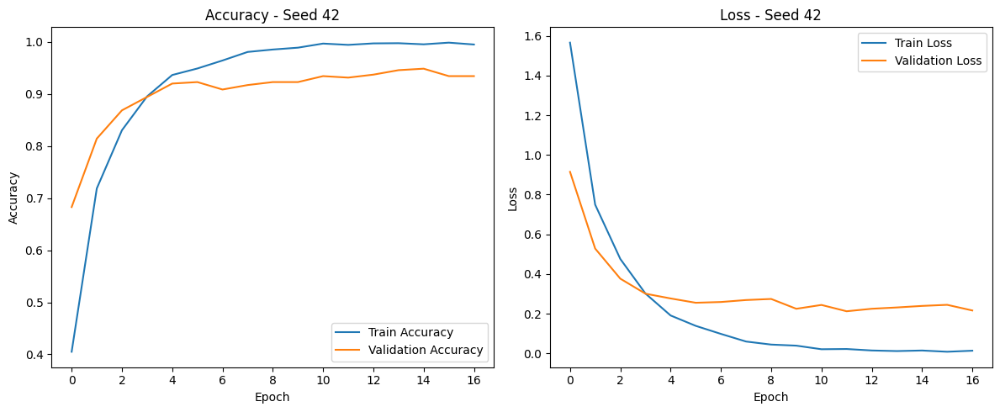

Seed 42 completed and results saved.

Running seed: 123
Train: 2800
Validation: 350
Test: 350
Class weights: {0: np.float64(1.0), 1: np.float64(1.0), 2: np.float64(1.0), 3: np.float64(1.0), 4: np.float64(1.0), 5: np.float64(1.0), 6: np.float64(1.0)}
Total parameters: 23,602,055
Trainable parameters: 8,933,383
Non-trainable parameters: 14,668,672
Epoch 1/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 37s 253ms/step - accuracy: 0.2837 - loss: 1.9019 - val_accuracy: 0.7343 - val_loss: 0.7193
Epoch 2/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 15s 133ms/step - accuracy: 0.7103 - loss: 0.7583 - val_accuracy: 0.8543 - val_loss: 0.4589
Epoch 3/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 16s 136ms/step - accuracy: 0.8289 - loss: 0.4549 - val_accuracy: 0.8743 - val_loss: 0.3487
Epoch 4/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 16s 137ms/step - accuracy: 0.8973 - loss: 0.2808 - val_accuracy: 0.8914 - val_loss: 0.3195
Epoch 5/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 15s 134ms/step - accuracy: 0.9230 - loss: 0.2052 - val_accuracy: 0.9000 - val_loss: 0.2457
Epoch 6

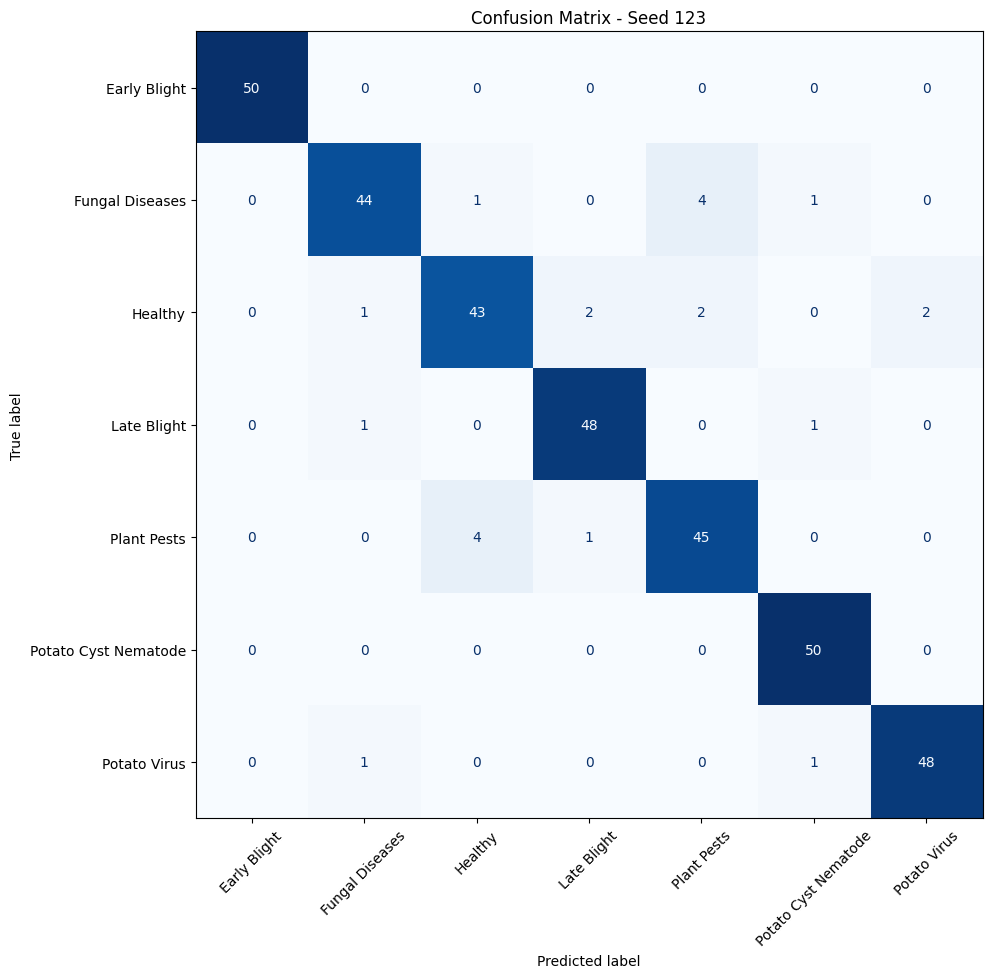

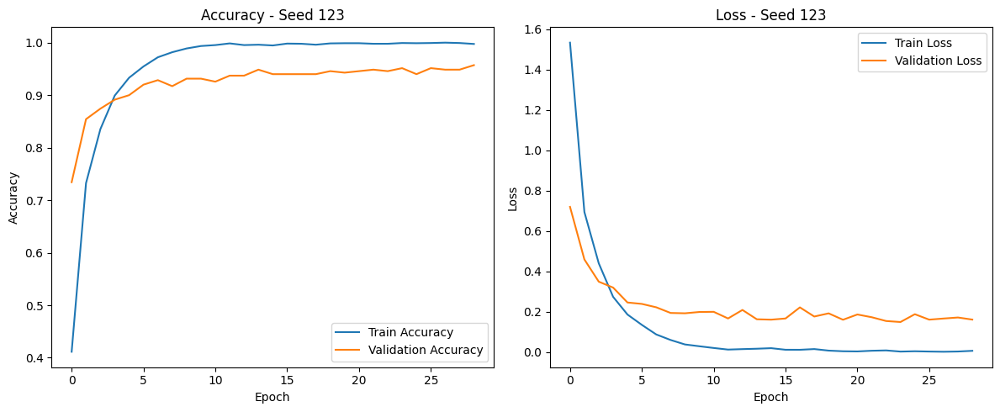

Seed 123 completed and results saved.

Running seed: 2024
Train: 2800
Validation: 350
Test: 350
Class weights: {0: np.float64(1.0), 1: np.float64(1.0), 2: np.float64(1.0), 3: np.float64(1.0), 4: np.float64(1.0), 5: np.float64(1.0), 6: np.float64(1.0)}
Total parameters: 23,602,055
Trainable parameters: 8,933,383
Non-trainable parameters: 14,668,672
Epoch 1/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 38s 252ms/step - accuracy: 0.2743 - loss: 2.0311 - val_accuracy: 0.6857 - val_loss: 0.8486
Epoch 2/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 15s 133ms/step - accuracy: 0.6729 - loss: 0.8803 - val_accuracy: 0.7971 - val_loss: 0.4856
Epoch 3/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 16s 136ms/step - accuracy: 0.8317 - loss: 0.4649 - val_accuracy: 0.8629 - val_loss: 0.3762
Epoch 4/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 16s 138ms/step - accuracy: 0.8829 - loss: 0.3236 - val_accuracy: 0.9086 - val_loss: 0.2879
Epoch 5/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 15s 134ms/step - accuracy: 0.9314 - loss: 0.1976 - val_accuracy: 0.8971 - val_loss: 0.2641
Epoch

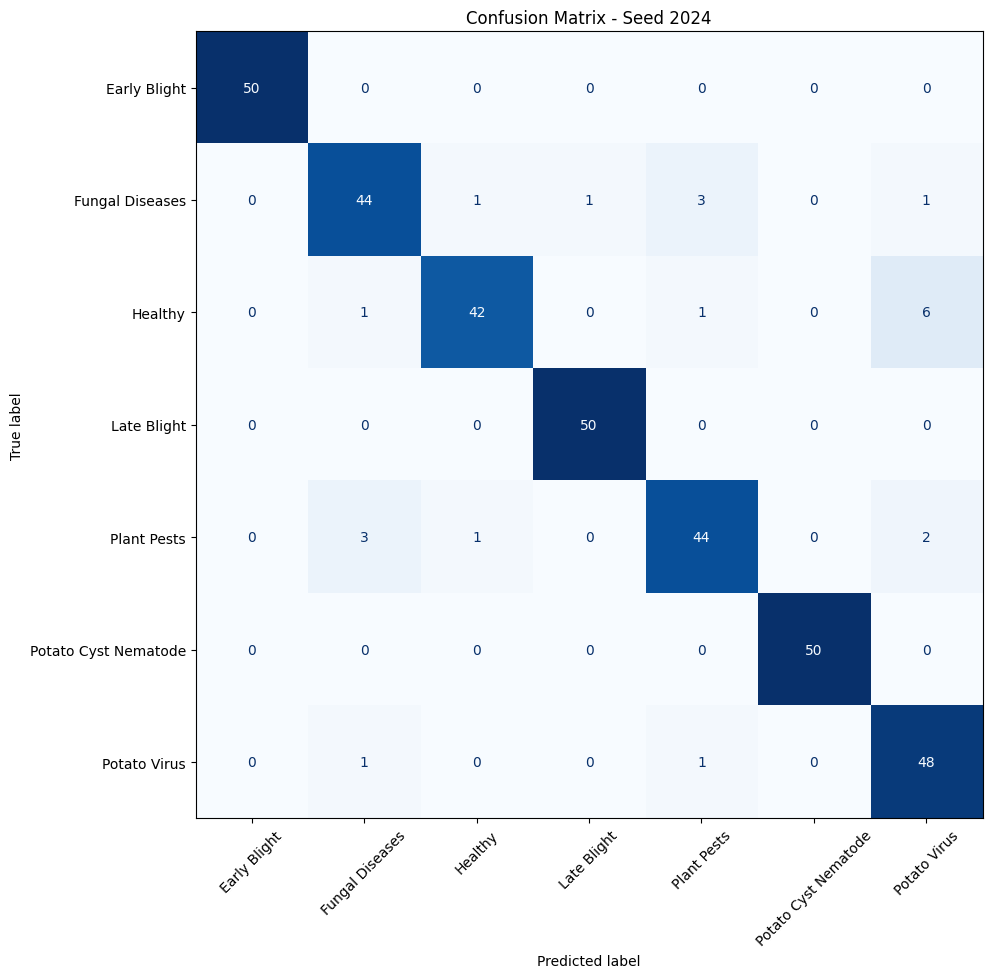

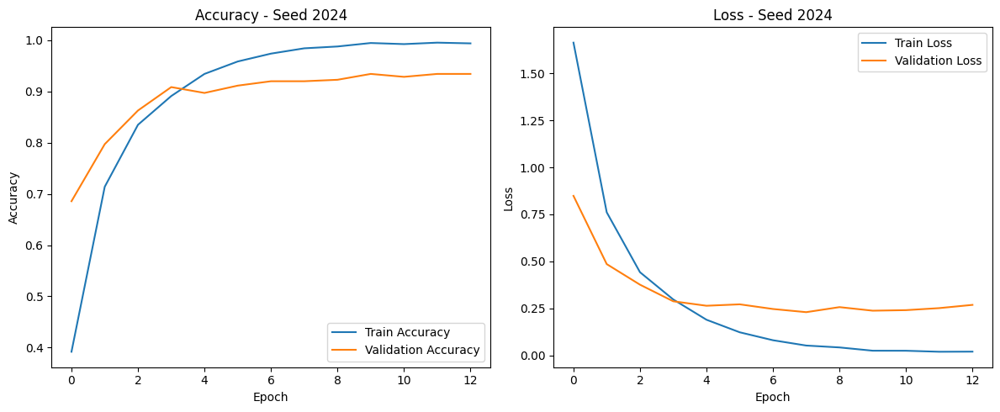

Seed 2024 completed and results saved.

Running seed: 3407
Train: 2800
Validation: 350
Test: 350
Class weights: {0: np.float64(1.0), 1: np.float64(1.0), 2: np.float64(1.0), 3: np.float64(1.0), 4: np.float64(1.0), 5: np.float64(1.0), 6: np.float64(1.0)}
Total parameters: 23,602,055
Trainable parameters: 8,933,383
Non-trainable parameters: 14,668,672
Epoch 1/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 37s 253ms/step - accuracy: 0.2966 - loss: 1.9109 - val_accuracy: 0.7400 - val_loss: 0.7388
Epoch 2/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 15s 135ms/step - accuracy: 0.7199 - loss: 0.7700 - val_accuracy: 0.8486 - val_loss: 0.4369
Epoch 3/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 16s 137ms/step - accuracy: 0.8404 - loss: 0.4275 - val_accuracy: 0.8829 - val_loss: 0.3368
Epoch 4/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 16s 136ms/step - accuracy: 0.8976 - loss: 0.2832 - val_accuracy: 0.9200 - val_loss: 0.2722
Epoch 5/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 15s 133ms/step - accuracy: 0.9377 - loss: 0.1811 - val_accuracy: 0.9086 - val_loss: 0.2552
Epoc

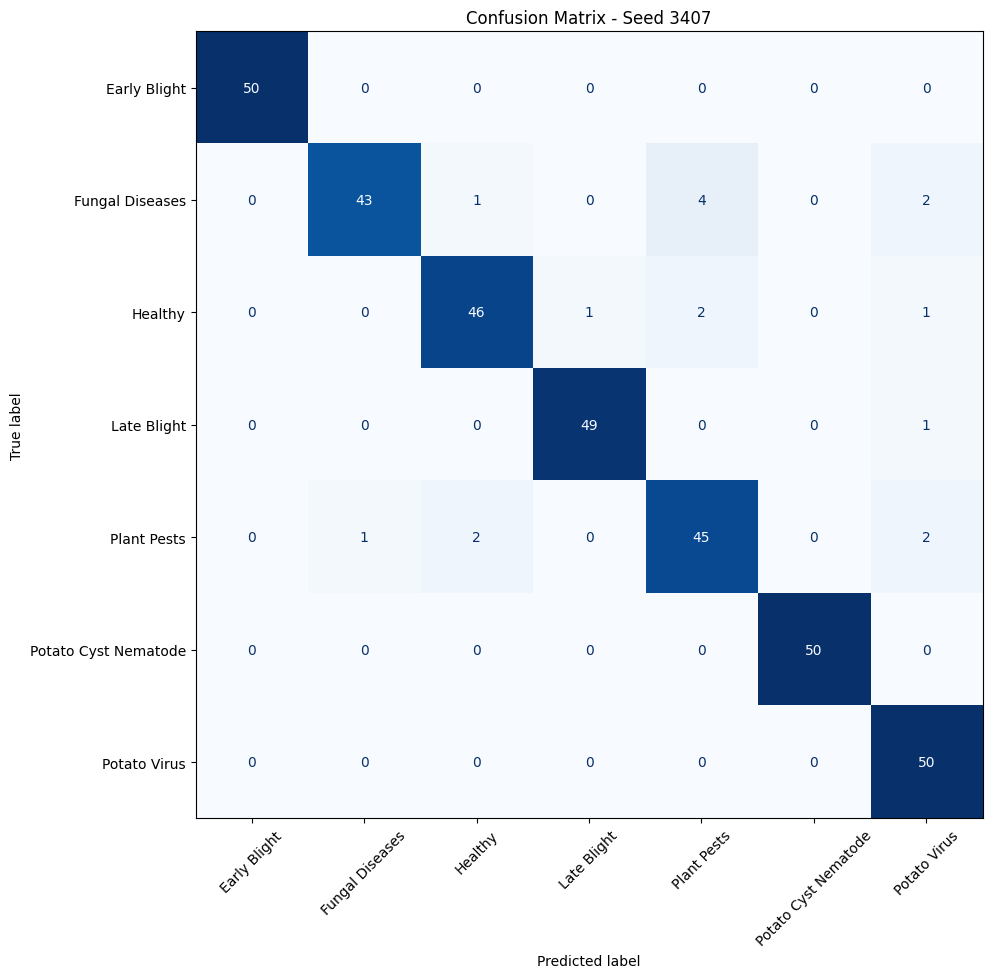

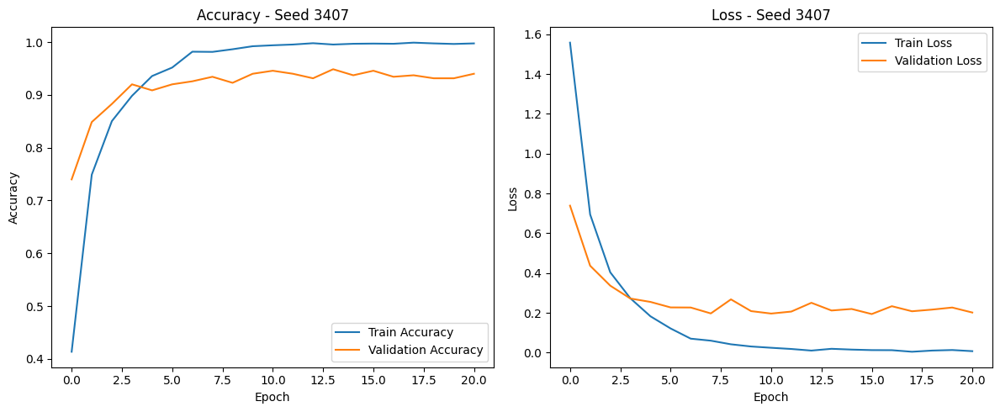

Seed 3407 completed and results saved.

Running seed: 777
Train: 2800
Validation: 350
Test: 350
Class weights: {0: np.float64(1.0), 1: np.float64(1.0), 2: np.float64(1.0), 3: np.float64(1.0), 4: np.float64(1.0), 5: np.float64(1.0), 6: np.float64(1.0)}
Total parameters: 23,602,055
Trainable parameters: 8,933,383
Non-trainable parameters: 14,668,672
Epoch 1/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 38s 253ms/step - accuracy: 0.2309 - loss: 2.0247 - val_accuracy: 0.6829 - val_loss: 0.9181
Epoch 2/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 15s 133ms/step - accuracy: 0.6974 - loss: 0.8678 - val_accuracy: 0.8114 - val_loss: 0.4848
Epoch 3/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 15s 136ms/step - accuracy: 0.8109 - loss: 0.4913 - val_accuracy: 0.8914 - val_loss: 0.3470
Epoch 4/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 16s 138ms/step - accuracy: 0.8974 - loss: 0.2947 - val_accuracy: 0.9086 - val_loss: 0.2757
Epoch 5/50
88/88 ━━━━━━━━━━━━━━━━━━━━ 15s 134ms/step - accuracy: 0.9372 - loss: 0.1947 - val_accuracy: 0.9229 - val_loss: 0.2383
Epoch

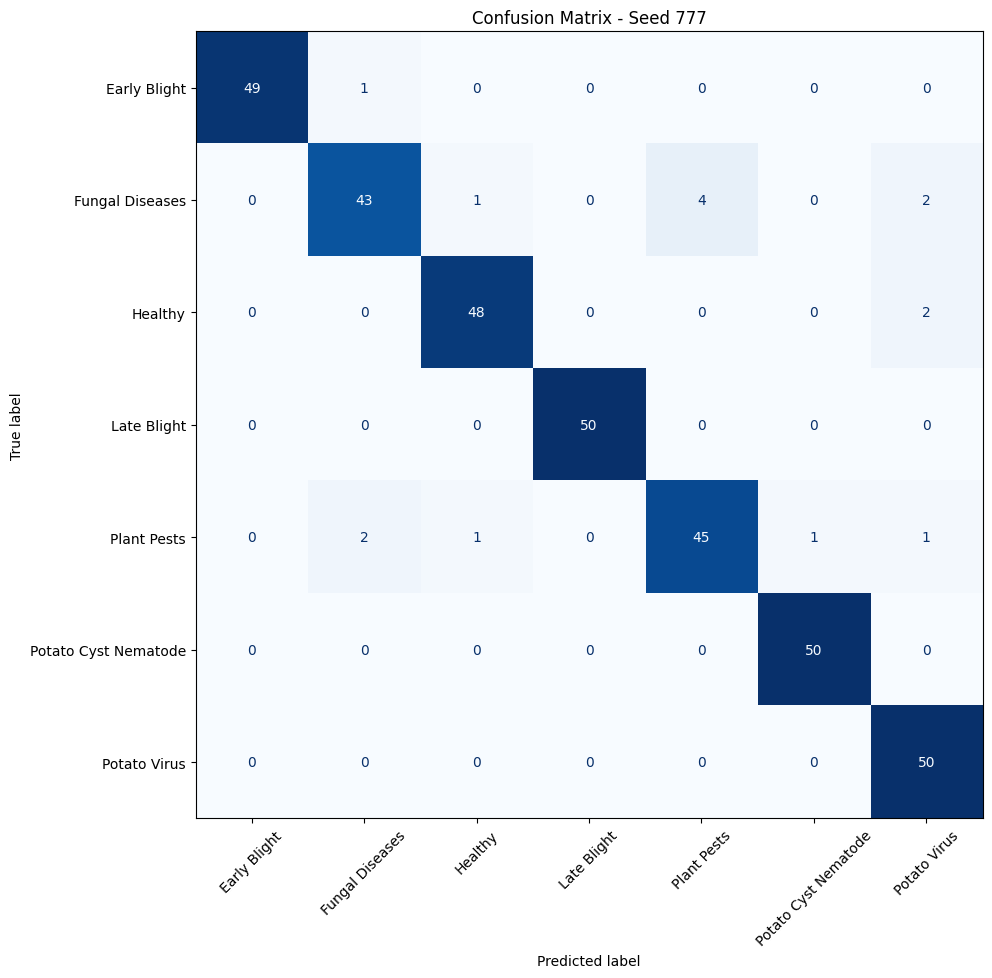

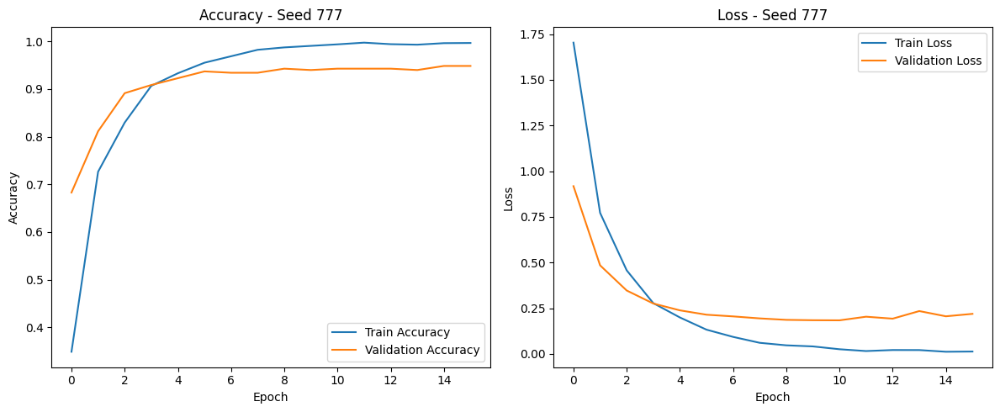

Seed 777 completed and results saved.

All seed results:
   seed  num_classes  test_accuracy  test_loss  stopped_epoch  best_epoch  \
0    42            7       0.945714   0.180402             17          12   
1   123            7       0.937143   0.215762             29          24   
2  2024            7       0.937143   0.251289             13           8   
3  3407            7       0.951429   0.185302             21          16   
4   777            7       0.957143   0.124990             16          11   

   macro_precision  macro_recall  macro_f1  weighted_precision  ...  \
0         0.946712      0.945714  0.945775            0.946712  ...   
1         0.936990      0.937143  0.936746            0.936990  ...   
2         0.938994      0.937143  0.936956            0.938994  ...   
3         0.953037      0.951429  0.951239            0.953037  ...   
4         0.957519      0.957143  0.956758            0.957519  ...   

   weighted_f1  total_params  trainable_params  non_t

In [11]:
all_results = []

for seed in SEEDS:
    result = run_single_seed(seed)
    all_results.append(result)

    # Save results immediately after each completed seed
    results_df = pd.DataFrame(all_results)
    results_df.to_csv(
        f"{EXPERIMENT_NAME}_results_per_seed.csv",
        index=False
    )

    print(f"Seed {seed} completed and results saved.")

print("\nAll seed results:")
print(pd.DataFrame(all_results))

In [12]:
results_df = pd.DataFrame(all_results)

csv_path = f"{EXPERIMENT_NAME}_multiseed_results.csv"
results_df.to_csv(csv_path, index=False)

print("Saved results to:", csv_path)
results_df


Saved results to: ResNet50_7class_multiseed_results.csv


,seed,num_classes,test_accuracy,test_loss,stopped_epoch,best_epoch,macro_precision,macro_recall,macro_f1,weighted_precision,...,weighted_f1,total_params,trainable_params,non_trainable_params,model_path,history_path,plot_path,confusion_matrix_path,classification_report_path,predictions_path
0,42,7,0.945714,0.180402,17,12,0.946712,0.945714,0.945775,0.946712,...,0.945775,23602055,8933383,14668672,models/ResNet50_7class_seed_42.keras,history/ResNet50_7class_seed_42_history.pkl,history/ResNet50_7class_seed_42_accuracy_loss.png,history/ResNet50_7class_seed_42_confusion_matr...,reports/ResNet50_7class_seed_42_classification...,predictions/ResNet50_7class_seed_42_test_predi...
1,123,7,0.937143,0.215762,29,24,0.936990,0.937143,0.936746,0.936990,...,0.936746,23602055,8933383,14668672,models/ResNet50_7class_seed_123.keras,history/ResNet50_7class_seed_123_history.pkl,history/ResNet50_7class_seed_123_accuracy_loss...,history/ResNet50_7class_seed_123_confusion_mat...,reports/ResNet50_7class_seed_123_classificatio...,predictions/ResNet50_7class_seed_123_test_pred...
2,2024,7,0.937143,0.251289,13,8,0.938994,0.937143,0.936956,0.938994,...,0.936956,23602055,8933383,14668672,models/ResNet50_7class_seed_2024.keras,history/ResNet50_7class_seed_2024_history.pkl,history/ResNet50_7class_seed_2024_accuracy_los...,history/ResNet50_7class_seed_2024_confusion_ma...,reports/ResNet50_7class_seed_2024_classificati...,predictions/ResNet50_7class_seed_2024_test_pre...
3,3407,7,0.951429,0.185302,21,16,0.953037,0.951429,0.951239,0.953037,...,0.951239,23602055,8933383,14668672,models/ResNet50_7class_seed_3407.keras,history/ResNet50_7class_seed_3407_history.pkl,history/ResNet50_7class_seed_3407_accuracy_los...,history/ResNet50_7class_seed_3407_confusion_ma...,reports/ResNet50_7class_seed_3407_classificati...,predictions/ResNet50_7class_seed_3407_test_pre...
4,777,7,0.957143,0.124990,16,11,0.957519,0.957143,0.956758,0.957519,...,0.956758,23602055,8933383,14668672,models/ResNet50_7class_seed_777.keras,history/ResNet50_7class_seed_777_history.pkl,history/ResNet50_7class_seed_777_accuracy_loss...,history/ResNet50_7class_seed_777_confusion_mat...,reports/ResNet50_7class_seed_777_classificatio...,predictions/ResNet50_7class_seed_777_test_pred...


In [13]:

# ============================================================
# ResNet-50 (7-Class): Multi-Seed Summary
# ============================================================

metrics = [
    "test_accuracy",
    "test_loss",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "weighted_precision",
    "weighted_recall",
    "weighted_f1",
    "stopped_epoch",
    "best_epoch"
]

summary_rows = []

for metric in metrics:
    values = results_df[metric].astype(float).values

    summary_rows.append({
        "metric": metric,
        "mean": np.mean(values),
        "std": np.std(values, ddof=0),
        "min": np.min(values),
        "max": np.max(values)
    })

summary_df = pd.DataFrame(summary_rows)

# Save summary results
summary_csv_path = f"{EXPERIMENT_NAME}_multiseed_summary.csv"
summary_df.to_csv(summary_csv_path, index=False)

print("Multi-seed summary report")
print("=" * 70)
display(summary_df)

print("\nSaved summary report to:", summary_csv_path)

# ============================================================
# Paper-Ready Summary (Mean ± SD)
# ============================================================

print("\nPaper-ready summary (Mean ± SD)")
print("=" * 70)

percentage_metrics = [
    ("test_accuracy", "Accuracy"),
    ("macro_precision", "Macro Precision"),
    ("macro_recall", "Macro Recall"),
    ("macro_f1", "Macro F1"),
    ("weighted_precision", "Weighted Precision"),
    ("weighted_recall", "Weighted Recall"),
    ("weighted_f1", "Weighted F1")
]

for metric, label in percentage_metrics:
    values = results_df[metric].astype(float).values * 100

    print(
        f"{label}: "
        f"{np.mean(values):.2f} ± "
        f"{np.std(values, ddof=0):.2f}%"
    )

# Test loss (not a percentage)
loss_values = results_df["test_loss"].astype(float).values

print(
    f"Test Loss: "
    f"{np.mean(loss_values):.4f} ± "
    f"{np.std(loss_values, ddof=0):.4f}"
)

# Training epochs
for metric, label in [
    ("stopped_epoch", "Stopped Epoch"),
    ("best_epoch", "Best Epoch")
]:
    values = results_df[metric].astype(float).values

    print(
        f"{label}: "
        f"{np.mean(values):.2f} ± "
        f"{np.std(values, ddof=0):.2f}"
    )

print("\nExperiment:", EXPERIMENT_NAME)
print("Number of seeds:", len(results_df))
print("Seeds:", SEEDS)


Multi-seed summary report


,metric,mean,std,min,max
0,test_accuracy,0.945714,0.007877,0.937143,0.957143
1,test_loss,0.191549,0.041829,0.124990,0.251289
2,macro_precision,0.946650,0.007885,0.936990,0.957519
3,macro_recall,0.945714,0.007877,0.937143,0.957143
4,macro_f1,0.945495,0.007866,0.936746,0.956758
5,weighted_precision,0.946650,0.007885,0.936990,0.957519
6,weighted_recall,0.945714,0.007877,0.937143,0.957143
7,weighted_f1,0.945495,0.007866,0.936746,0.956758
8,stopped_epoch,19.200000,5.528110,13.000000,29.000000
9,best_epoch,14.200000,5.528110,8.000000,24.000000



Saved summary report to: ResNet50_7class_multiseed_summary.csv

Paper-ready summary (Mean ± SD)
Accuracy: 94.57 ± 0.79%
Macro Precision: 94.67 ± 0.79%
Macro Recall: 94.57 ± 0.79%
Macro F1: 94.55 ± 0.79%
Weighted Precision: 94.67 ± 0.79%
Weighted Recall: 94.57 ± 0.79%
Weighted F1: 94.55 ± 0.79%
Test Loss: 0.1915 ± 0.0418
Stopped Epoch: 19.20 ± 5.53
Best Epoch: 14.20 ± 5.53

Experiment: ResNet50_7class
Number of seeds: 5
Seeds: [42, 123, 2024, 3407, 777]


In [14]:

# ============================================================
# Select Representative ResNet-50 Model
# ============================================================

mean_acc = results_df["test_accuracy"].mean()

results_df["distance_from_mean_accuracy"] = (
    results_df["test_accuracy"] - mean_acc
).abs()

representative_row = results_df.sort_values(
    ["distance_from_mean_accuracy", "seed"]
).iloc[0]

MODEL_PATH = representative_row["model_path"]
SEED_TO_ANALYZE = int(representative_row["seed"])

print("Mean accuracy:", mean_acc)
print("Representative seed:", SEED_TO_ANALYZE)
print("Representative model:", MODEL_PATH)

representative_row


Mean accuracy: 0.945714282989502
Representative seed: 42
Representative model: models/ResNet50_7class_seed_42.keras


seed                                                                          42
num_classes                                                                    7
test_accuracy                                                           0.945714
test_loss                                                               0.180402
stopped_epoch                                                                 17
best_epoch                                                                    12
macro_precision                                                         0.946712
macro_recall                                                            0.945714
macro_f1                                                                0.945775
weighted_precision                                                      0.946712
weighted_recall                                                         0.945714
weighted_f1                                                             0.945775
total_params                

In [15]:

from tensorflow.keras.models import load_model

MODEL_TYPE = "resnet50"
IMAGE_SIZE = (224, 224)

model = load_model(MODEL_PATH, compile=False)

print("Loaded model:", MODEL_PATH)
print("Model type:", MODEL_TYPE)
print("Input shape:", model.input_shape)


Loaded model: models/ResNet50_7class_seed_42.keras
Model type: resnet50
Input shape: (None, 224, 224, 3)


In [16]:

# ============================================================
# Reconstruct Test Set for Representative ResNet-50 Model
# ============================================================

X_train, X_temp, y_train, y_temp = train_test_split(
    file_paths,
    labels,
    test_size=0.20,
    stratify=labels,
    random_state=SEED_TO_ANALYZE
)

X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    stratify=y_temp,
    random_state=SEED_TO_ANALYZE
)

print("Representative seed:", SEED_TO_ANALYZE)
print("Test images:", len(X_test))


Representative seed: 42
Test images: 350


In [17]:

# ============================================================
# ResNet-50: Test Predictions for Grad-CAM and Three-Way Analysis
# ============================================================

from tensorflow.keras.applications.resnet50 import preprocess_input

def load_image_for_model(image_path):
    image_raw = tf.io.read_file(image_path)

    image = tf.image.decode_image(
        image_raw,
        channels=3,
        expand_animations=False
    )
    image.set_shape([None, None, 3])

    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32)

    # RGB image for visualization
    original_image = tf.clip_by_value(
        image, 0.0, 255.0
    ).numpy().astype(np.uint8)

    # ResNet-50 preprocessing
    processed_image = preprocess_input(image)
    processed_image = tf.expand_dims(processed_image, axis=0)

    return processed_image, original_image


idx_to_class = {
    i: name for i, name in enumerate(class_names)
}

class_to_idx = {
    name: i for i, name in enumerate(class_names)
}

records = []

for image_path, true_label in zip(X_test, y_test):
    processed_image, _ = load_image_for_model(image_path)

    probs = model.predict(
        processed_image,
        verbose=0
    )[0]

    pred_label = int(np.argmax(probs))
    confidence = float(np.max(probs))

    record = {
        "image_path": image_path,
        "true_label": int(true_label),
        "true_class": idx_to_class[int(true_label)],
        "predicted_label": pred_label,
        "pred_class": idx_to_class[pred_label],
        "confidence": confidence,
        "correct": int(true_label) == pred_label
    }

    # Save complete probability distribution
    for i in range(NUM_CLASSES):
        record[f"prob_class_{i}"] = float(probs[i])

    records.append(record)

pred_df = pd.DataFrame(records)

pred_csv_path = (
    f"test_predictions_{MODEL_TYPE}_"
    f"{NUM_CLASSES}class_seed_{SEED_TO_ANALYZE}.csv"
)

pred_df.to_csv(pred_csv_path, index=False)

print("Saved predictions to:", pred_csv_path)
print("Total predictions:", len(pred_df))
print("Test accuracy:", pred_df["correct"].mean())

display(pred_df.head())


Saved predictions to: test_predictions_resnet50_7class_seed_42.csv
Total predictions: 350
Test accuracy: 0.9457142857142857


,image_path,true_label,true_class,predicted_label,pred_class,confidence,correct,prob_class_0,prob_class_1,prob_class_2,prob_class_3,prob_class_4,prob_class_5,prob_class_6
0,/kaggle/input/datasets/shahadhossin567r7455/po...,6,Potato Virus,6,Potato Virus,0.997316,True,1.458766e-07,2.310920e-03,1.886229e-04,1.709320e-04,1.468588e-06,1.146256e-05,9.973164e-01
1,/kaggle/input/datasets/shahadhossin567r7455/po...,0,Early Blight,0,Early Blight,0.996791,True,9.967907e-01,3.043313e-06,9.197035e-11,3.088039e-03,9.547675e-11,9.081856e-05,2.737049e-05
2,/kaggle/input/datasets/shahadhossin567r7455/po...,4,Plant Pests,4,Plant Pests,0.999551,True,1.043801e-06,7.109943e-07,1.035333e-05,8.654076e-09,9.995515e-01,2.296653e-04,2.067631e-04
3,/kaggle/input/datasets/shahadhossin567r7455/po...,1,Fungal Diseases,1,Fungal Diseases,0.999980,True,2.157185e-07,9.999801e-01,1.128612e-05,1.343386e-06,6.901415e-06,9.611482e-10,1.539270e-07
4,/kaggle/input/datasets/shahadhossin567r7455/po...,2,Healthy,2,Healthy,0.789590,True,2.036757e-05,1.492955e-02,7.895896e-01,8.972540e-04,1.942257e-01,1.455862e-04,1.918830e-04


In [18]:

# ============================================================
# ResNet-50: Three-Way Decision Region Assignment
# ============================================================

ALPHA = 0.90
BETA = 0.60

assert 0 <= BETA < ALPHA <= 1

def assign_three_way_region(confidence):
    if confidence >= ALPHA:
        return "Accept"
    elif confidence >= BETA:
        return "Defer"
    else:
        return "Reject"


twd_df = pred_df.copy()

twd_df["decision_region"] = (
    twd_df["confidence"].apply(assign_three_way_region)
)

print("Three-Way Decision Thresholds:")
print(f"Accept: confidence >= {ALPHA}")
print(f"Defer:  {BETA} <= confidence < {ALPHA}")
print(f"Reject: confidence < {BETA}")

print("\nDecision Region Distribution:")
print(
    twd_df["decision_region"]
    .value_counts()
    .reindex(["Accept", "Defer", "Reject"], fill_value=0)
)

display(twd_df.head())


Three-Way Decision Thresholds:
Accept: confidence >= 0.9
Defer:  0.6 <= confidence < 0.9
Reject: confidence < 0.6

Decision Region Distribution:
decision_region
Accept    307
Defer      36
Reject      7
Name: count, dtype: int64


,image_path,true_label,true_class,predicted_label,pred_class,confidence,correct,prob_class_0,prob_class_1,prob_class_2,prob_class_3,prob_class_4,prob_class_5,prob_class_6,decision_region
0,/kaggle/input/datasets/shahadhossin567r7455/po...,6,Potato Virus,6,Potato Virus,0.997316,True,1.458766e-07,2.310920e-03,1.886229e-04,1.709320e-04,1.468588e-06,1.146256e-05,9.973164e-01,Accept
1,/kaggle/input/datasets/shahadhossin567r7455/po...,0,Early Blight,0,Early Blight,0.996791,True,9.967907e-01,3.043313e-06,9.197035e-11,3.088039e-03,9.547675e-11,9.081856e-05,2.737049e-05,Accept
2,/kaggle/input/datasets/shahadhossin567r7455/po...,4,Plant Pests,4,Plant Pests,0.999551,True,1.043801e-06,7.109943e-07,1.035333e-05,8.654076e-09,9.995515e-01,2.296653e-04,2.067631e-04,Accept
3,/kaggle/input/datasets/shahadhossin567r7455/po...,1,Fungal Diseases,1,Fungal Diseases,0.999980,True,2.157185e-07,9.999801e-01,1.128612e-05,1.343386e-06,6.901415e-06,9.611482e-10,1.539270e-07,Accept
4,/kaggle/input/datasets/shahadhossin567r7455/po...,2,Healthy,2,Healthy,0.789590,True,2.036757e-05,1.492955e-02,7.895896e-01,8.972540e-04,1.942257e-01,1.455862e-04,1.918830e-04,Defer


In [19]:

# ============================================================
# ResNet-50: Three-Way Decision Performance Analysis
# ============================================================

total_samples = len(twd_df)

region_order = ["Accept", "Defer", "Reject"]

# Region counts and percentages
region_counts = (
    twd_df["decision_region"]
    .value_counts()
    .reindex(region_order, fill_value=0)
)

region_percentages = (
    region_counts / total_samples
) * 100

print("Three-Way Decision Counts")
print("=" * 70)

for region in region_order:
    print(
        f"{region}: {region_counts[region]} samples "
        f"({region_percentages[region]:.2f}%)"
    )

# ============================================================
# Accuracy and Error Rate by Region
# ============================================================

print("\nDecision Region Accuracy")
print("=" * 70)

region_results = []

for region in region_order:
    region_df = twd_df[
        twd_df["decision_region"] == region
    ]

    count = len(region_df)

    if count > 0:
        accuracy = region_df["correct"].mean()
        error_rate = 1.0 - accuracy
    else:
        accuracy = np.nan
        error_rate = np.nan

    region_results.append({
        "region": region,
        "count": count,
        "percentage": 100 * count / total_samples,
        "accuracy": accuracy,
        "error_rate": error_rate
    })

region_summary_df = pd.DataFrame(region_results)

display(region_summary_df)

# ============================================================
# Accept Region Reliability
# ============================================================

accept_df = twd_df[
    twd_df["decision_region"] == "Accept"
]

if len(accept_df) > 0:
    accept_accuracy = accept_df["correct"].mean()
    accept_error_rate = 1.0 - accept_accuracy
else:
    accept_accuracy = np.nan
    accept_error_rate = np.nan

print("\nAccept Region")
print("=" * 70)
print(f"Accept accuracy: {accept_accuracy:.4f}")
print(f"Accept error rate: {accept_error_rate:.4f}")

# ============================================================
# Wrong Prediction Capture Rate (WCR)
# ============================================================

wrong_df = twd_df[
    twd_df["correct"] == False
]

wrong_captured_df = wrong_df[
    wrong_df["decision_region"].isin(
        ["Defer", "Reject"]
    )
]

num_wrong_total = len(wrong_df)
num_wrong_captured = len(wrong_captured_df)

if num_wrong_total > 0:
    wrong_capture_rate = (
        num_wrong_captured / num_wrong_total
    )
else:
    wrong_capture_rate = np.nan

print("\nWrong Prediction Analysis")
print("=" * 70)

print(f"Total wrong predictions: {num_wrong_total}")
print(
    f"Wrong predictions captured by Defer/Reject: "
    f"{num_wrong_captured}"
)
print(f"Wrong capture rate: {wrong_capture_rate:.4f}")

# ============================================================
# Save Results
# ============================================================

region_csv_path = (
    f"{EXPERIMENT_NAME}_three_way_region_summary_"
    f"seed_{SEED_TO_ANALYZE}.csv"
)

region_summary_df.to_csv(
    region_csv_path,
    index=False
)

print("\nSaved region summary to:", region_csv_path)


Three-Way Decision Counts
Accept: 307 samples (87.71%)
Defer: 36 samples (10.29%)
Reject: 7 samples (2.00%)

Decision Region Accuracy


,region,count,percentage,accuracy,error_rate
0,Accept,307,87.714286,0.980456,0.019544
1,Defer,36,10.285714,0.722222,0.277778
2,Reject,7,2.000000,0.571429,0.428571



Accept Region
Accept accuracy: 0.9805
Accept error rate: 0.0195

Wrong Prediction Analysis
Total wrong predictions: 19
Wrong predictions captured by Defer/Reject: 13
Wrong capture rate: 0.6842

Saved region summary to: ResNet50_7class_three_way_region_summary_seed_42.csv


In [20]:

# ============================================================
# ResNet-50: Class-Wise Three-Way Decision Distribution
# ============================================================

region_order = ["Accept", "Defer", "Reject"]

# Class-wise counts
class_region_counts = pd.crosstab(
    twd_df["true_class"],
    twd_df["decision_region"]
).reindex(
    index=class_names,
    columns=region_order,
    fill_value=0
)

# Class-wise percentages
class_region_percentages = (
    class_region_counts.div(
        class_region_counts.sum(axis=1).replace(0, np.nan),
        axis=0
    ) * 100
)

print("Class-wise Accept / Defer / Reject counts:")
display(class_region_counts)

print("\nClass-wise Accept / Defer / Reject percentages:")
display(class_region_percentages.round(2))

# Save results
counts_path = (
    f"{EXPERIMENT_NAME}_class_region_counts_"
    f"seed_{SEED_TO_ANALYZE}.csv"
)

percentages_path = (
    f"{EXPERIMENT_NAME}_class_region_percentages_"
    f"seed_{SEED_TO_ANALYZE}.csv"
)

class_region_counts.to_csv(counts_path)
class_region_percentages.to_csv(percentages_path)

print("\nSaved files:")
print(counts_path)
print(percentages_path)


Class-wise Accept / Defer / Reject counts:


decision_region,Accept,Defer,Reject
true_class,,,
Early Blight,50,0,0
Fungal Diseases,41,8,1
Healthy,38,9,3
Late Blight,46,4,0
Plant Pests,42,6,2
Potato Cyst Nematode,48,2,0
Potato Virus,42,7,1



Class-wise Accept / Defer / Reject percentages:


decision_region,Accept,Defer,Reject
true_class,,,
Early Blight,100.0,0.0,0.0
Fungal Diseases,82.0,16.0,2.0
Healthy,76.0,18.0,6.0
Late Blight,92.0,8.0,0.0
Plant Pests,84.0,12.0,4.0
Potato Cyst Nematode,96.0,4.0,0.0
Potato Virus,84.0,14.0,2.0



Saved files:
ResNet50_7class_class_region_counts_seed_42.csv
ResNet50_7class_class_region_percentages_seed_42.csv


In [21]:

# ============================================================
# ResNet-50: Save Three-Way Decision Results
# ============================================================

three_way_csv = (
    f"three_way_decision_{MODEL_TYPE}_"
    f"{NUM_CLASSES}class_seed_{SEED_TO_ANALYZE}.csv"
)

twd_df.to_csv(three_way_csv, index=False)

# ============================================================
# Three-Way Decision Summary
# ============================================================

summary = {
    "model": MODEL_TYPE,
    "seed": SEED_TO_ANALYZE,
    "num_classes": NUM_CLASSES,
    "alpha": ALPHA,
    "beta": BETA,
    "total_samples": total_samples,
    "overall_accuracy": float(twd_df["correct"].mean()),

    "accept_count": int(region_counts["Accept"]),
    "defer_count": int(region_counts["Defer"]),
    "reject_count": int(region_counts["Reject"]),

    "accept_percentage": float(region_percentages["Accept"]),
    "defer_percentage": float(region_percentages["Defer"]),
    "reject_percentage": float(region_percentages["Reject"]),

    "accept_accuracy": float(accept_accuracy),
    "accept_error_rate": float(accept_error_rate),

    "total_wrong_predictions": int(num_wrong_total),
    "wrong_predictions_captured_by_defer_reject": int(num_wrong_captured),
    "wrong_capture_rate": float(wrong_capture_rate)
}

three_way_summary_df = pd.DataFrame([summary])

summary_csv = (
    f"three_way_decision_summary_{MODEL_TYPE}_"
    f"{NUM_CLASSES}class_seed_{SEED_TO_ANALYZE}.csv"
)

three_way_summary_df.to_csv(summary_csv, index=False)

print("Saved:", three_way_csv)
print("Saved:", summary_csv)

display(three_way_summary_df)



Saved: three_way_decision_resnet50_7class_seed_42.csv
Saved: three_way_decision_summary_resnet50_7class_seed_42.csv


,model,seed,num_classes,alpha,beta,total_samples,overall_accuracy,accept_count,defer_count,reject_count,accept_percentage,defer_percentage,reject_percentage,accept_accuracy,accept_error_rate,total_wrong_predictions,wrong_predictions_captured_by_defer_reject,wrong_capture_rate
0,resnet50,42,7,0.9,0.6,350,0.945714,307,36,7,87.714286,10.285714,2.0,0.980456,0.019544,19,13,0.684211


In [22]:

# ============================================================
# ResNet-50: Grad-CAM Configuration
# ============================================================

SAMPLES_PER_GROUP = 3

OUTPUT_DIR = (
    f"gradcam_{MODEL_TYPE}_"
    f"{NUM_CLASSES}class_seed_{SEED_TO_ANALYZE}"
)

os.makedirs(OUTPUT_DIR, exist_ok=True)

print("Grad-CAM output folder:", OUTPUT_DIR)
print("Samples per group:", SAMPLES_PER_GROUP)
print("Class names:", class_names)


Grad-CAM output folder: gradcam_resnet50_7class_seed_42
Samples per group: 3
Class names: ['Early Blight', 'Fungal Diseases', 'Healthy', 'Late Blight', 'Plant Pests', 'Potato Cyst Nematode', 'Potato Virus']


In [23]:

# ============================================================
# ResNet-50: Select Grad-CAM Analysis Samples
# ============================================================

analysis_groups = {
    "correct_fungal_diseases": {
        "true": "Fungal Diseases",
        "pred": "Fungal Diseases"
    },
    "fungal_diseases_as_plant_pests": {
        "true": "Fungal Diseases",
        "pred": "Plant Pests"
    },
    "plant_pests_as_fungal_diseases": {
        "true": "Plant Pests",
        "pred": "Fungal Diseases"
    },
    "healthy_as_potato_virus": {
        "true": "Healthy",
        "pred": "Potato Virus"
    },
    "potato_virus_as_healthy": {
        "true": "Potato Virus",
        "pred": "Healthy"
    },
    "correct_early_blight": {
        "true": "Early Blight",
        "pred": "Early Blight"
    },
    "correct_late_blight": {
        "true": "Late Blight",
        "pred": "Late Blight"
    }
}

region_order = ["Accept", "Defer", "Reject"]

# Verify the required classes exist
required_classes = set()

for rule in analysis_groups.values():
    required_classes.update([rule["true"], rule["pred"]])

missing_classes = required_classes - set(class_names)

assert not missing_classes, (
    f"Classes not found in dataset: {missing_classes}"
)

selected_samples = []

for group_name, rule in analysis_groups.items():

    group_df = twd_df[
        (twd_df["true_class"] == rule["true"]) &
        (twd_df["pred_class"] == rule["pred"])
    ].copy()

    # Deterministic ordering
    group_df = group_df.sort_values(
        ["confidence", "image_path"],
        ascending=[False, True]
    )

    group_selected = []
    selected_paths = set()

    # First select one sample per available region
    for region in region_order:

        if len(group_selected) >= SAMPLES_PER_GROUP:
            break

        region_df = group_df[
            group_df["decision_region"] == region
        ]

        if not region_df.empty:
            row = region_df.iloc[0]

            group_selected.append(row)
            selected_paths.add(row["image_path"])

    # Fill remaining slots with highest-confidence samples
    remaining_df = group_df[
        ~group_df["image_path"].isin(selected_paths)
    ]

    remaining_slots = (
        SAMPLES_PER_GROUP - len(group_selected)
    )

    for _, row in remaining_df.head(remaining_slots).iterrows():
        group_selected.append(row)

    print(
        f"{group_name}: selected "
        f"{len(group_selected)} samples"
    )

    for row in group_selected:
        sample = row.to_dict()
        sample["group"] = group_name
        selected_samples.append(sample)

selected_df = pd.DataFrame(selected_samples)

selected_csv_path = os.path.join(
    OUTPUT_DIR,
    "selected_gradcam_samples.csv"
)

selected_df.to_csv(
    selected_csv_path,
    index=False
)

print("\nSaved selected samples to:", selected_csv_path)
print("Total selected samples:", len(selected_df))

if not selected_df.empty:
    print("\nSelected samples by group and decision region:")
    display(
        pd.crosstab(
            selected_df["group"],
            selected_df["decision_region"]
        ).reindex(
            index=list(analysis_groups.keys()),
            columns=region_order,
            fill_value=0
        )
    )

display(selected_df)


correct_fungal_diseases: selected 3 samples
fungal_diseases_as_plant_pests: selected 3 samples
plant_pests_as_fungal_diseases: selected 2 samples
healthy_as_potato_virus: selected 1 samples
potato_virus_as_healthy: selected 0 samples
correct_early_blight: selected 3 samples
correct_late_blight: selected 3 samples

Saved selected samples to: gradcam_resnet50_7class_seed_42/selected_gradcam_samples.csv
Total selected samples: 15

Selected samples by group and decision region:


decision_region,Accept,Defer,Reject
group,,,
correct_fungal_diseases,2,1,0
fungal_diseases_as_plant_pests,2,1,0
plant_pests_as_fungal_diseases,1,0,1
healthy_as_potato_virus,0,1,0
potato_virus_as_healthy,0,0,0
correct_early_blight,3,0,0
correct_late_blight,2,1,0


,image_path,true_label,true_class,predicted_label,pred_class,confidence,correct,prob_class_0,prob_class_1,prob_class_2,prob_class_3,prob_class_4,prob_class_5,prob_class_6,decision_region,group
0,/kaggle/input/datasets/shahadhossin567r7455/po...,1,Fungal Diseases,1,Fungal Diseases,0.999999,True,9.159116e-07,9.999990e-01,9.022081e-16,6.218351e-10,1.596945e-08,3.206064e-11,5.237448e-13,Accept,correct_fungal_diseases
1,/kaggle/input/datasets/shahadhossin567r7455/po...,1,Fungal Diseases,1,Fungal Diseases,0.863316,True,5.569093e-07,8.633161e-01,8.708052e-03,1.107511e-01,1.720537e-02,8.884117e-08,1.865482e-05,Defer,correct_fungal_diseases
2,/kaggle/input/datasets/shahadhossin567r7455/po...,1,Fungal Diseases,1,Fungal Diseases,0.999999,True,2.184919e-08,9.999990e-01,6.412925e-11,2.357562e-07,7.456263e-07,5.759820e-09,6.873078e-10,Accept,correct_fungal_diseases
3,/kaggle/input/datasets/shahadhossin567r7455/po...,1,Fungal Diseases,4,Plant Pests,0.997744,False,1.139443e-06,2.240111e-03,6.992000e-07,1.449849e-05,9.977436e-01,1.049476e-08,1.160204e-10,Accept,fungal_diseases_as_plant_pests
4,/kaggle/input/datasets/shahadhossin567r7455/po...,1,Fungal Diseases,4,Plant Pests,0.814319,False,3.542731e-06,1.852882e-01,6.342550e-08,5.530931e-06,8.143185e-01,3.742764e-04,9.810155e-06,Defer,fungal_diseases_as_plant_pests
5,/kaggle/input/datasets/shahadhossin567r7455/po...,1,Fungal Diseases,4,Plant Pests,0.971303,False,6.689872e-09,2.782767e-02,7.847830e-05,9.894367e-05,9.713030e-01,1.746480e-06,6.901083e-04,Accept,fungal_diseases_as_plant_pests
6,/kaggle/input/datasets/shahadhossin567r7455/po...,4,Plant Pests,1,Fungal Diseases,0.997919,False,2.745036e-07,9.979190e-01,1.497467e-03,3.943004e-06,3.632402e-04,1.863510e-04,2.981656e-05,Accept,plant_pests_as_fungal_diseases
7,/kaggle/input/datasets/shahadhossin567r7455/po...,4,Plant Pests,1,Fungal Diseases,0.590133,False,1.327002e-06,5.901327e-01,1.511298e-06,9.464926e-05,4.097280e-01,2.708250e-05,1.479180e-05,Reject,plant_pests_as_fungal_diseases
8,/kaggle/input/datasets/shahadhossin567r7455/po...,2,Healthy,6,Potato Virus,0.668169,False,6.248176e-07,1.837333e-01,1.291323e-01,1.177543e-03,1.778658e-02,1.174598e-06,6.681685e-01,Defer,healthy_as_potato_virus
9,/kaggle/input/datasets/shahadhossin567r7455/po...,0,Early Blight,0,Early Blight,1.000000,True,1.000000e+00,5.120474e-12,1.534836e-17,2.218947e-12,4.052375e-12,7.627167e-13,5.080160e-16,Accept,correct_early_blight


In [24]:

# ============================================================
# ResNet-50: Identify Grad-CAM Target Layer
# ============================================================

LAST_CONV_LAYER_NAME = "conv5_block3_out"

# Verify the target layer exists
try:
    target_layer = model.get_layer(LAST_CONV_LAYER_NAME)
except ValueError:
    raise ValueError(
        f"Layer '{LAST_CONV_LAYER_NAME}' not found. "
        "Check the loaded ResNet-50 architecture."
    )

print("Grad-CAM target layer:", target_layer.name)
print("Target layer output shape:", target_layer.output.shape)

# ============================================================
# Build Grad-CAM Model
# ============================================================

gradcam_model = tf.keras.models.Model(
    inputs=model.inputs,
    outputs=[
        target_layer.output,
        model.outputs[0]
    ]
)

print("Grad-CAM model created successfully.")
print("Grad-CAM feature shape:", gradcam_model.outputs[0].shape)
print("Prediction shape:", gradcam_model.outputs[1].shape)


Grad-CAM target layer: conv5_block3_out
Target layer output shape: (None, 7, 7, 2048)
Grad-CAM model created successfully.
Grad-CAM feature shape: (None, 7, 7, 2048)
Prediction shape: (None, 7)


In [25]:

# ============================================================
# ResNet-50: Grad-CAM Heatmap Generation
# ============================================================

def make_gradcam_heatmap(
    processed_image,
    gradcam_model,
    class_index=None
):
    with tf.GradientTape() as tape:
        conv_outputs, predictions = gradcam_model(
            processed_image,
            training=False
        )

        if class_index is None:
            class_index = tf.argmax(
                predictions[0],
                output_type=tf.int32
            )

        class_index = tf.cast(class_index, tf.int32)

        # Corrected: no [:, 0] after tf.gather
        class_score = tf.gather(
            predictions,
            class_index,
            axis=1
        )

    grads = tape.gradient(
        class_score,
        conv_outputs
    )

    if grads is None:
        raise ValueError(
            "Gradients are None. Grad-CAM graph is disconnected."
        )

    pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0.0)

    heatmap = heatmap / (
        tf.reduce_max(heatmap) + 1e-8
    )

    return heatmap.numpy()


# ============================================================
# Overlay Grad-CAM on Original Image
# ============================================================

def overlay_heatmap(
    original_image,
    heatmap,
    alpha=0.4,
    cmap="jet"
):
    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis],
        (
            original_image.shape[0],
            original_image.shape[1]
        )
    ).numpy().squeeze()

    colormap = plt.get_cmap(cmap)

    colored_heatmap = (
        colormap(heatmap_resized)[:, :, :3]
    )

    colored_heatmap = np.uint8(
        255 * colored_heatmap
    )

    overlay = (
        alpha * colored_heatmap.astype(np.float32)
        + (1 - alpha) * original_image.astype(np.float32)
    )

    overlay = np.clip(
        overlay, 0, 255
    ).astype(np.uint8)

    return overlay


# ============================================================
# Generate and Save Grad-CAM Figure
# ============================================================

def save_gradcam_figure(sample):

    image_path = sample["image_path"]
    true_class = sample["true_class"]
    pred_class = sample["pred_class"]
    confidence = float(sample["confidence"])
    group = sample["group"]

    decision_region = sample.get(
        "decision_region",
        assign_three_way_region(confidence)
    )

    processed_image, original_image = (
        load_image_for_model(image_path)
    )

    pred_index = class_to_idx[pred_class]

    heatmap = make_gradcam_heatmap(
        processed_image=processed_image,
        gradcam_model=gradcam_model,
        class_index=pred_index
    )

    overlay = overlay_heatmap(
        original_image,
        heatmap,
        alpha=0.4
    )

    fig, axes = plt.subplots(
        1, 2,
        figsize=(10, 5)
    )

    axes[0].imshow(original_image)
    axes[0].set_title("Original Image")
    axes[0].axis("off")

    axes[1].imshow(overlay)
    axes[1].set_title("Grad-CAM Overlay")
    axes[1].axis("off")

    title = (
        f"Group: {group}\n"
        f"True: {true_class} | "
        f"Predicted: {pred_class}\n"
        f"Confidence: {confidence:.4f} | "
        f"Decision: {decision_region}"
    )

    fig.suptitle(
        title,
        fontsize=11
    )

    plt.tight_layout()

    # Unique filename using image path hash
    import hashlib

    image_id = hashlib.sha256(
        str(image_path).encode("utf-8")
    ).hexdigest()[:12]

    safe_name = os.path.splitext(
        os.path.basename(image_path)
    )[0]

    save_path = os.path.join(
        OUTPUT_DIR,
        f"{group}_{safe_name}_{image_id}_gradcam.png"
    )

    fig.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)

    return save_path


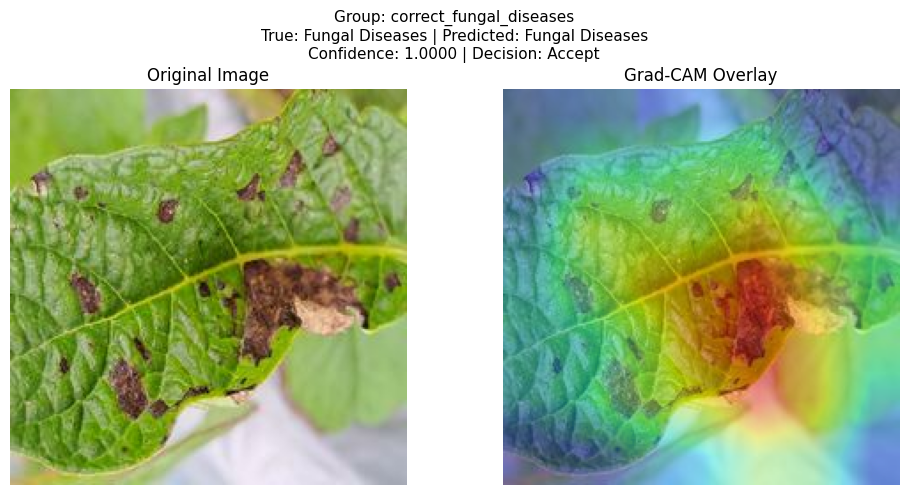

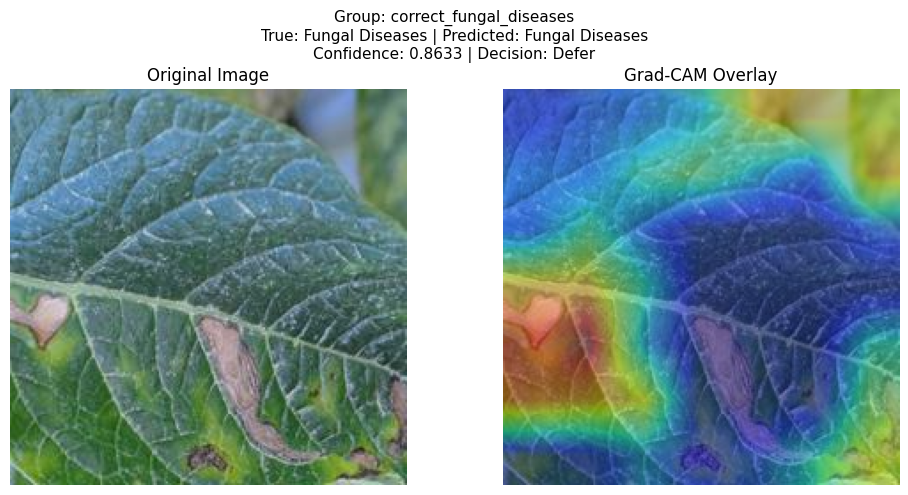

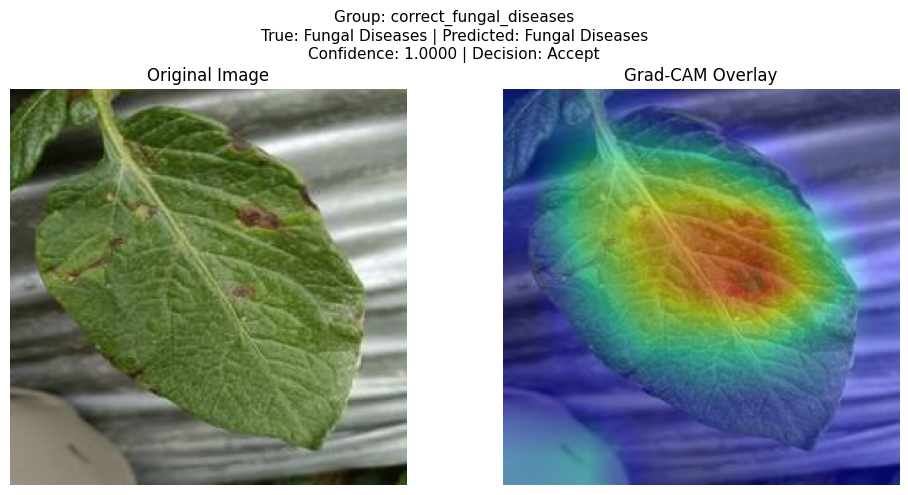

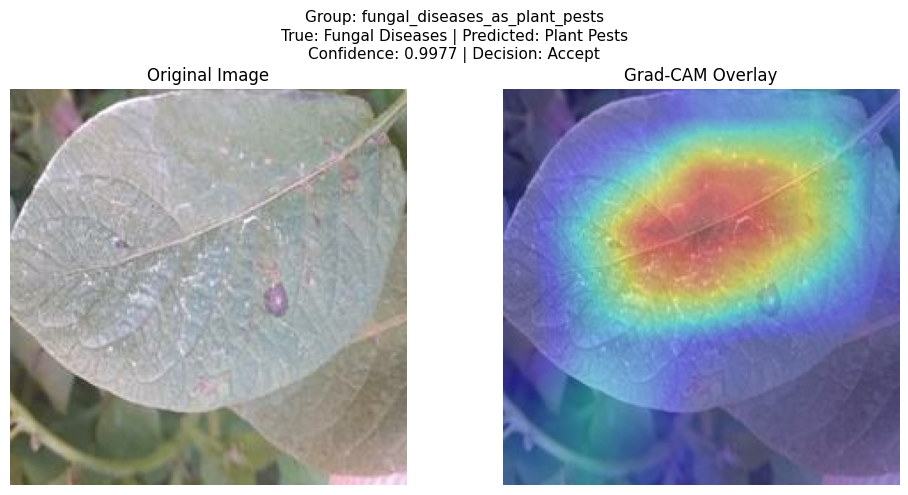

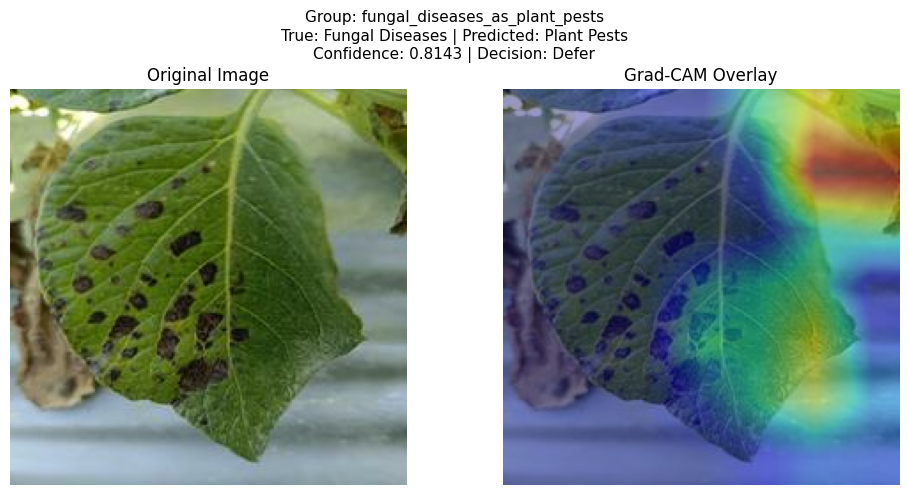

...

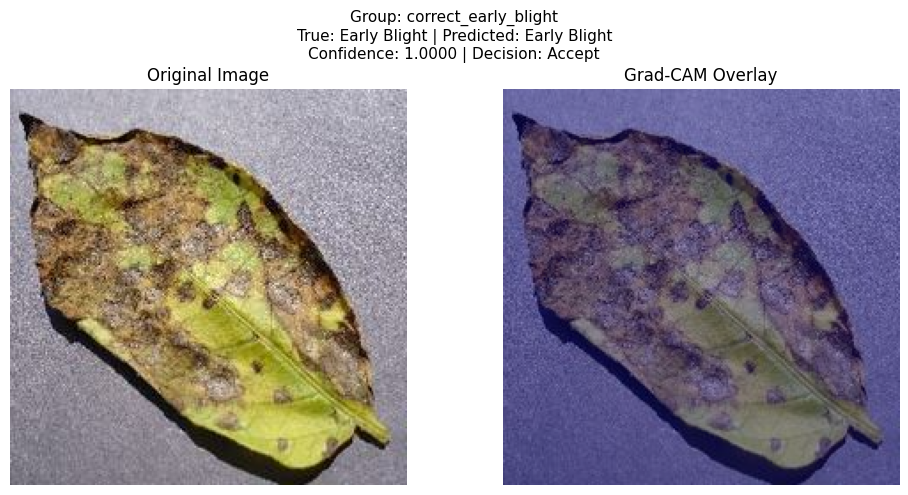

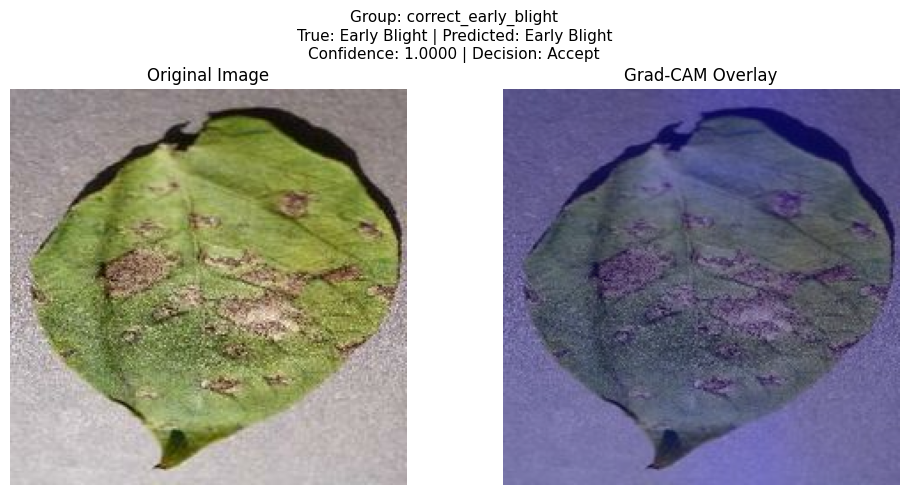

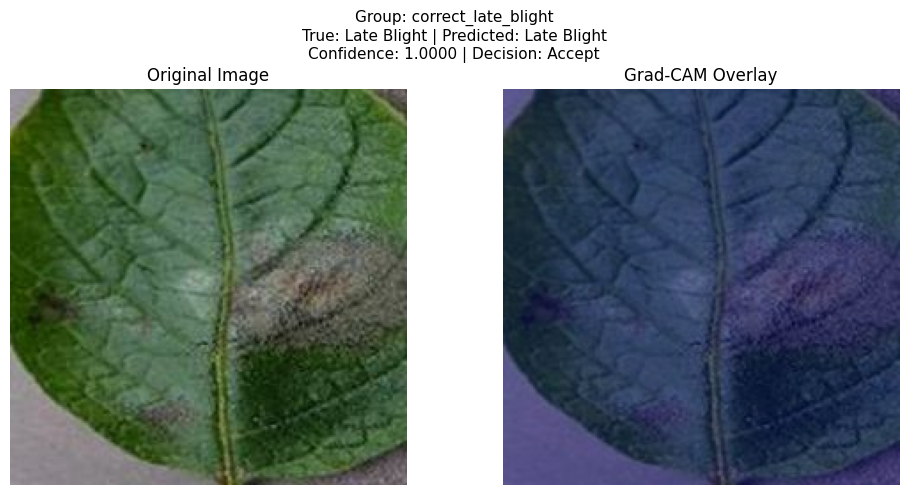

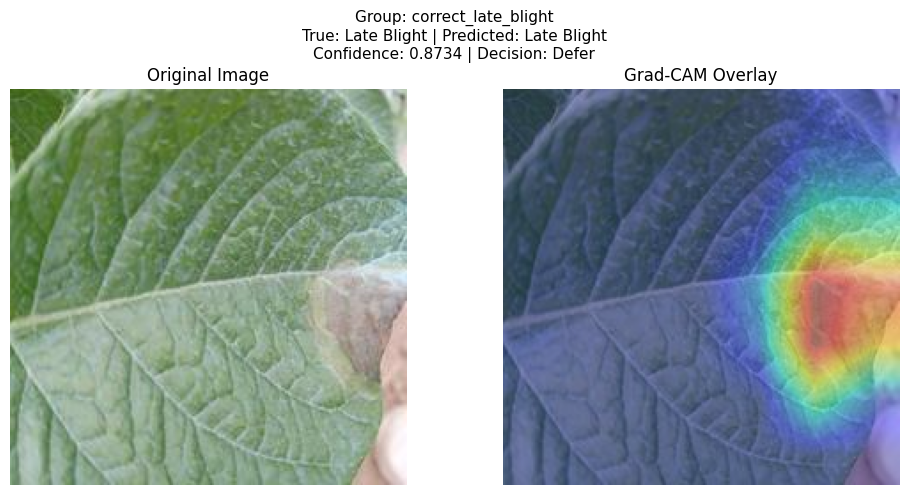

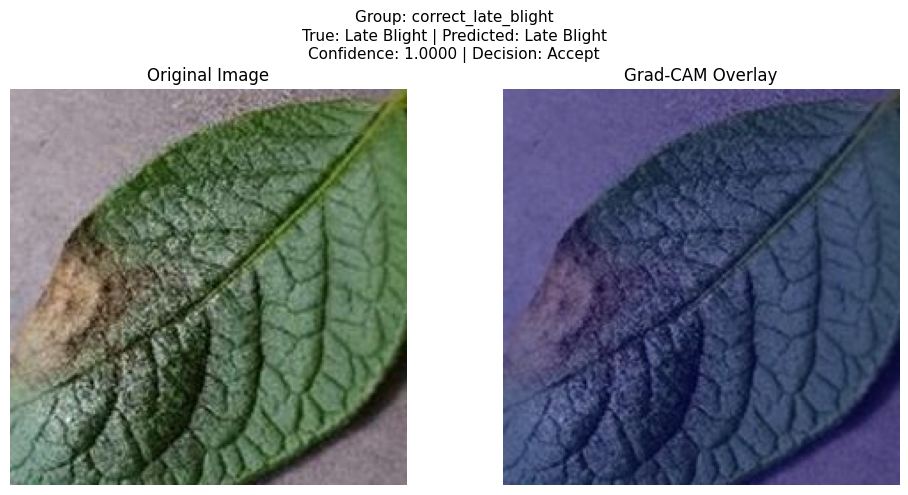


Saved Grad-CAM figures:
gradcam_resnet50_7class_seed_42/correct_fungal_diseases_fungal  (25)_70e55d547ae2_gradcam.png
gradcam_resnet50_7class_seed_42/correct_fungal_diseases_fungal  (234)_66f78e50de0d_gradcam.png
gradcam_resnet50_7class_seed_42/correct_fungal_diseases_fungal  (468)_f3e93170a205_gradcam.png
gradcam_resnet50_7class_seed_42/fungal_diseases_as_plant_pests_fungal  (200)_84a8beecc733_gradcam.png
gradcam_resnet50_7class_seed_42/fungal_diseases_as_plant_pests_fungal  (483)_2d51172d9b12_gradcam.png
gradcam_resnet50_7class_seed_42/fungal_diseases_as_plant_pests_fungal  (201)_e16dd508a319_gradcam.png
gradcam_resnet50_7class_seed_42/plant_pests_as_fungal_diseases_plant pests (13)_1f753c382d26_gradcam.png
gradcam_resnet50_7class_seed_42/plant_pests_as_fungal_diseases_plant pests (51)_8727cad71264_gradcam.png
gradcam_resnet50_7class_seed_42/healthy_as_potato_virus_healthy (243)_fa4a3f802078_gradcam.png
gradcam_resnet50_7class_seed_42/correct_early_blight_early blight (110)_56086a5b

In [26]:

# ============================================================
# ResNet-50: Generate and Save All Selected Grad-CAM Figures
# ============================================================

saved_gradcam_paths = []

for _, sample in selected_df.iterrows():
    save_path = save_gradcam_figure(sample)
    saved_gradcam_paths.append(save_path)

print("\nSaved Grad-CAM figures:")
print("=" * 70)

for path in saved_gradcam_paths:
    print(path)

print("\nTotal Grad-CAM figures saved:", len(saved_gradcam_paths))
print("Output directory:", OUTPUT_DIR)


In [27]:

# ============================================================
# ResNet-50 (7-Class): Export Complete Experiment Results
# ============================================================

import os
import zipfile

PROJECT_EXPORT_NAME = "ICDM_7class_resnet50_outputs"

export_items = [
    "models",
    "history",
    "reports",
    "predictions",
    OUTPUT_DIR
]

# Include all experiment CSV and PNG files
export_items.extend([
    f for f in os.listdir(".")
    if f.lower().endswith((".csv", ".png"))
    and os.path.isfile(f)
])

zip_path = f"{PROJECT_EXPORT_NAME}.zip"

with zipfile.ZipFile(
    zip_path,
    "w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=6
) as zipf:

    for item in export_items:

        if os.path.isfile(item):
            zipf.write(item)

        elif os.path.isdir(item):
            for root, dirs, files in os.walk(item):
                for filename in files:
                    file_path = os.path.join(root, filename)
                    zipf.write(file_path)

print("Created:", zip_path)
print(
    "ZIP size:",
    round(os.path.getsize(zip_path) / (1024 ** 2), 2),
    "MB"
)

print("\nExport completed.")


Created: ICDM_7class_resnet50_outputs.zip
ZIP size: 742.39 MB

Export completed.
